In [1]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (classification_report,precision_score,recall_score,f1_score,roc_auc_score,average_precision_score,confusion_matrix)
from xgboost import XGBClassifier
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (LSTM,Dense,Dropout,Input)
from tensorflow.keras.callbacks import EarlyStopping

In [2]:
df = pd.read_csv("air_compressor_metro.csv").drop(columns="Unnamed: 0")
df["timestamp"] = pd.to_datetime(df["timestamp"])      # اول تبدیل، بعد sort
df = df.sort_values("timestamp").set_index("timestamp")

In [3]:
failure_events = [
    {
        "failure_id": 1,
        "start": pd.Timestamp("2020-04-18 00:00:00"),
        "end": pd.Timestamp("2020-04-18 23:59:00")
    },
    {
        "failure_id": 2,
        "start": pd.Timestamp("2020-05-29 23:30:00"),
        "end": pd.Timestamp("2020-05-30 06:00:00")
    },
    {
        "failure_id": 3,
        "start": pd.Timestamp("2020-06-05 10:00:00"),
        "end": pd.Timestamp("2020-06-07 14:30:00")
    },
    {
        "failure_id": 4,
        "start": pd.Timestamp("2020-07-15 14:30:00"),
        "end": pd.Timestamp("2020-07-15 19:00:00")
    }
]
DELTA = pd.Timedelta(hours=6)
raw_cols = ["TP2","TP3","H1","DV_pressure","Reservoirs","Oil_temperature",
            "Motor_current","COMP","DV_eletric","Towers"]

df["failure"] = 0
in_failure = pd.Series(False, index=df.index)

for ev in failure_events:
    pos = (df.index >= ev["start"] - DELTA) & (df.index < ev["start"])   # 6h قبل از خرابی
    df.loc[pos, "failure"] = 1
    in_failure |= (df.index >= ev["start"]) & (df.index <= ev["end"])    # خود بازه خرابی

df.loc[in_failure, raw_cols] = np.nan      # به جای حذف بعدی، NaN میکنیم
print(df["failure"].value_counts())

failure
0    1508621
1       8327
Name: count, dtype: int64


In [4]:
df_10min = df.resample("10min").agg({
    **{c: ["mean","std","min","max"] for c in
       ["TP2","TP3","H1","DV_pressure","Reservoirs","Oil_temperature","Motor_current"]},
    **{c: ["mean","std"] for c in ["COMP","DV_eletric","Towers"]},
    "failure": "max"})
df_10min.columns = ["_".join(c).strip("_") for c in df_10min.columns]

sensor_cols = ["TP2_mean","TP3_mean","H1_mean","DV_pressure_mean",
               "Reservoirs_mean","Oil_temperature_mean","Motor_current_mean"]
for col in sensor_cols:
    df_10min[f"{col}_1h_mean"] = df_10min[col].rolling(6).mean()
    df_10min[f"{col}_1h_std"]  = df_10min[col].rolling(6).std()

df_10min = df_10min.dropna().copy()        # ردیفهای نزدیک خرابی و gap ها حذف میشوند

# شماره بخش پیوسته (هر جا فاصله != 10 دقیقه، بخش جدید)
df_10min["segment"] = (df_10min.index.to_series().diff() != pd.Timedelta("10min")).cumsum()

y   = df_10min["failure_max"].astype(int)
seg = df_10min["segment"].to_numpy()
X   = df_10min.drop(columns=["failure_max", "segment"])
print(y.value_counts())

failure_max
0    23950
1      144
Name: count, dtype: int64


In [5]:
folds = []
for prev, ev in zip(failure_events[:-1], failure_events[1:]):
    train_mask = X.index < prev["end"]
    test_mask  = (X.index >= prev["end"]) & (X.index < ev["start"])
    folds.append({"failure_id": ev["failure_id"],
                  "train_mask": train_mask, "test_mask": test_mask})
    print(ev["failure_id"],
          "train pos:", int(y[train_mask].sum()), "| train neg:", int((y[train_mask]==0).sum()),
          "| test pos:", int(y[test_mask].sum()),  "| test neg:", int((y[test_mask]==0).sum()))

2 train pos: 36 | train neg: 9068 | test pos: 36 | test neg: 4329
3 train pos: 72 | train neg: 13397 | test pos: 36 | test neg: 727
4 train pos: 108 | train neg: 14124 | test pos: 36 | test neg: 4279


In [6]:
def make_sequences(X_scaled, y_arr, seg_arr, times, seq_len):
    Xs, ys, ts = [], [], []
    for s in np.unique(seg_arr):
        idx = np.where(seg_arr == s)[0]
        for k in range(seq_len - 1, len(idx)):
            w = idx[k - seq_len + 1 : k + 1]
            Xs.append(X_scaled[w]); ys.append(y_arr[idx[k]]); ts.append(times[idx[k]])
    return (np.array(Xs, dtype=np.float32),
            np.array(ys, dtype=np.int32),
            pd.DatetimeIndex(ts))

In [10]:
SEED, SEQ_LEN, THRESHOLD, EPOCHS = 42, 12, 0.5, 15
tf.keras.utils.set_random_seed(SEED)

results = {}
for fold in folds:
    fid = fold["failure_id"]
    scaler = StandardScaler().fit(X[fold["train_mask"]])         # فقط روی train
    X_scaled = scaler.transform(X).astype(np.float32)

    X_seq, y_seq, t_seq = make_sequences(X_scaled, y.to_numpy(), seg, X.index, SEQ_LEN)

    tr = t_seq.isin(X.index[fold["train_mask"]])
    te = t_seq.isin(X.index[fold["test_mask"]])
    X_tr, y_tr, X_te, y_te = X_seq[tr], y_seq[tr], X_seq[te], y_seq[te]

    n_neg, n_pos = int((y_tr == 0).sum()), int((y_tr == 1).sum())
    w1 = float(np.sqrt(n_neg / n_pos))                            # وزن نرمتر
    print(f"\n=== Failure {fid} === train {np.bincount(y_tr)} | test {np.bincount(y_te, minlength=2)} | w1={w1:.1f}")

    model = Sequential([
        Input(shape=(SEQ_LEN, X.shape[1])),
        LSTM(32), Dropout(0.2),
        Dense(16, activation="relu"), Dropout(0.2),
        Dense(1, activation="sigmoid")])
    model.compile(optimizer="adam", loss="binary_crossentropy")

    model.fit(X_tr, y_tr, epochs=EPOCHS, batch_size=64,
              class_weight={0: 1.0, 1: w1}, shuffle=True, verbose=0)
    # shuffle=True داخل train مشکلی ندارد، چون هر sequence خودش ترتیب زمانی را نگه میدارد

    y_prob = model.predict(X_te, verbose=0).ravel()
    y_pred = (y_prob >= THRESHOLD).astype(int)

    print(classification_report(y_te, y_pred, labels=[0,1],
          target_names=["Healthy","Failure"], zero_division=0, digits=4))
    print("CM:\n", confusion_matrix(y_te, y_pred, labels=[0,1]))
    if len(np.unique(y_te)) == 2:
        print("ROC-AUC:", roc_auc_score(y_te, y_prob), "| PR-AUC:", average_precision_score(y_te, y_prob))
    print("prob stats (pos):", pd.Series(y_prob[y_te==1]).describe()[["mean","max"]].to_dict())


=== Failure 2 === train [8518   36] | test [3993   36] | w1=15.4
              precision    recall  f1-score   support

     Healthy     0.9902    0.9098    0.9483      3993
     Failure     0.0000    0.0000    0.0000        36

    accuracy                         0.9017      4029
   macro avg     0.4951    0.4549    0.4742      4029
weighted avg     0.9813    0.9017    0.9398      4029

CM:
 [[3633  360]
 [  36    0]]
ROC-AUC: 0.2500834794223224 | PR-AUC: 0.005594628709963948
prob stats (pos): {'mean': 6.727885306645476e-07, 'max': 1.610014987818431e-05}

=== Failure 3 === train [12511    72] | test [669  36] | w1=13.2
              precision    recall  f1-score   support

     Healthy     0.9462    0.9462    0.9462       669
     Failure     0.0000    0.0000    0.0000        36

    accuracy                         0.8979       705
   macro avg     0.4731    0.4731    0.4731       705
weighted avg     0.8979    0.8979    0.8979       705

CM:
 [[633  36]
 [ 36   0]]
ROC-AUC: 0.2309

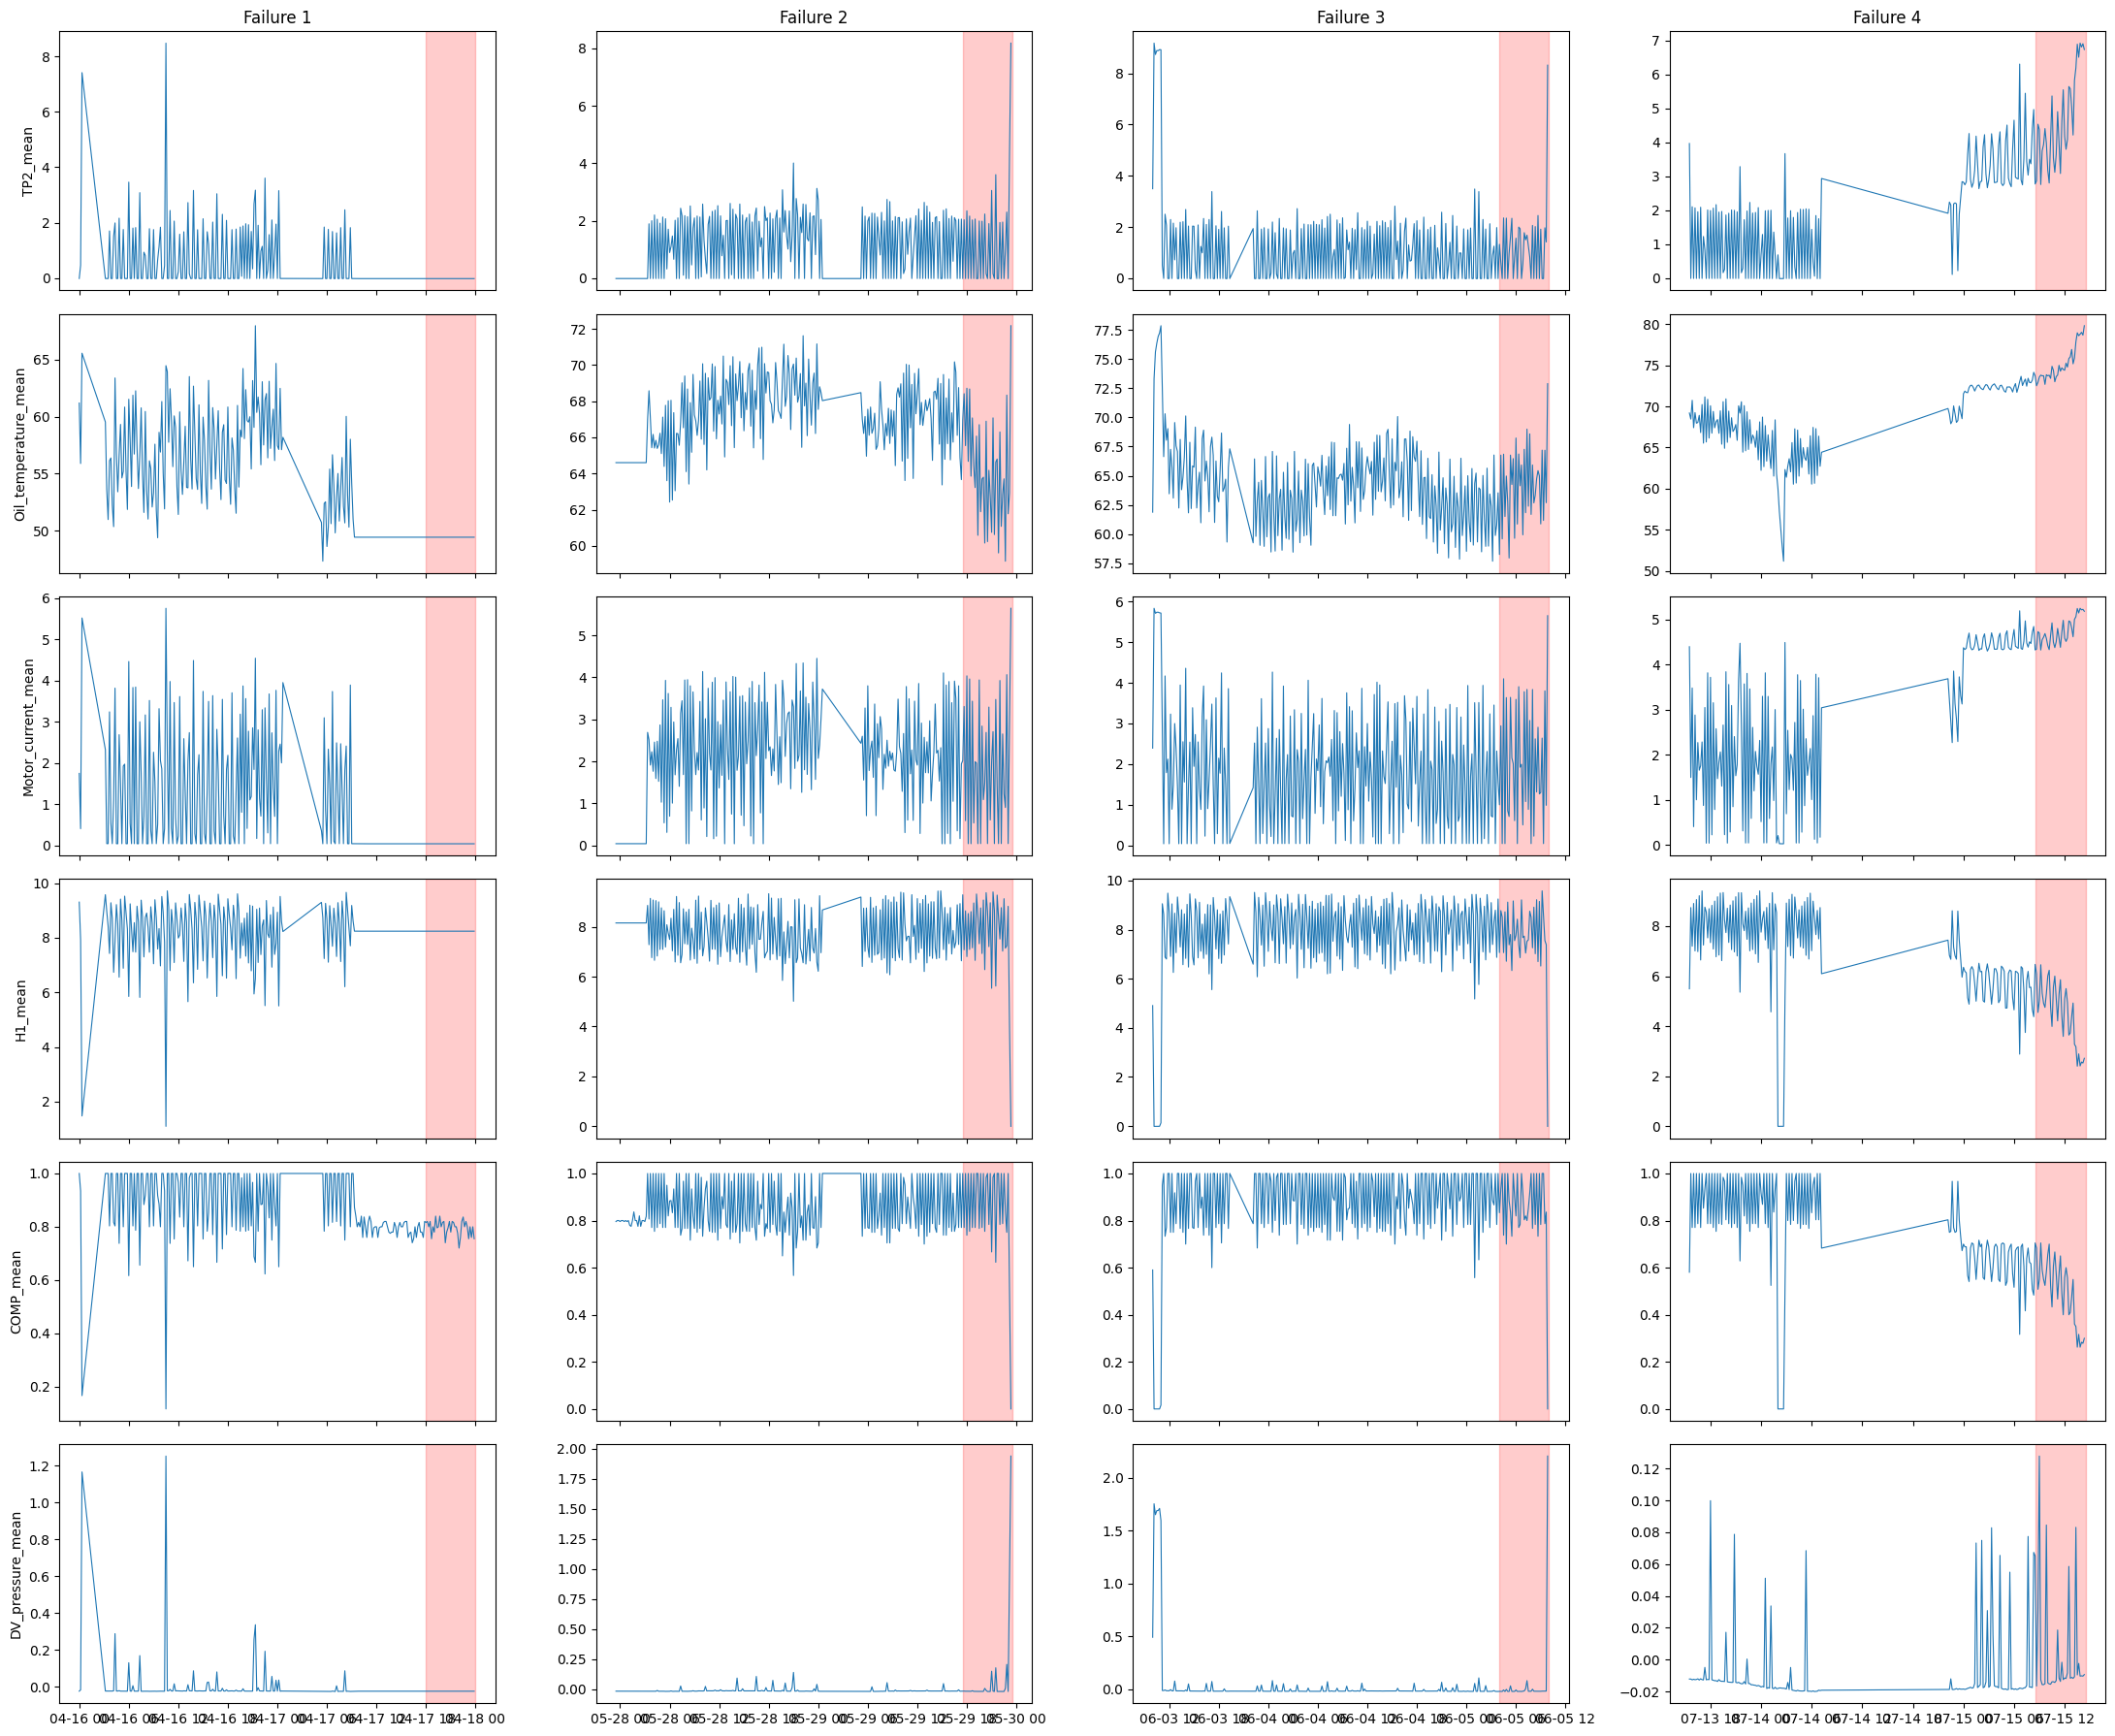

In [11]:
cols = ["TP2_mean", "Oil_temperature_mean", "Motor_current_mean",
        "H1_mean", "COMP_mean", "DV_pressure_mean"]

fig, axes = plt.subplots(len(cols), 4, figsize=(22, 3 * len(cols)), sharex="col")
for j, ev in enumerate(failure_events):
    s = ev["start"]
    w = df_10min.loc[s - pd.Timedelta(hours=48): s]
    for i, c in enumerate(cols):
        ax = axes[i, j]
        ax.plot(w.index, w[c], lw=0.8)
        ax.axvspan(s - DELTA, s, color="red", alpha=0.2)
        if j == 0:
            ax.set_ylabel(c)
    axes[0, j].set_title(f"Failure {ev['failure_id']}")
plt.tight_layout()
plt.show()

In [7]:
failure_events = [{
        "failure_id": 1,
        "start": pd.Timestamp("2020-04-18 00:00:00"),
        "end": pd.Timestamp("2020-04-18 23:59:00")},
    {
        "failure_id": 2,
        "start": pd.Timestamp("2020-05-29 23:30:00"),
        "end": pd.Timestamp("2020-05-30 06:00:00")},
    {
        "failure_id": 3,
        "start": pd.Timestamp("2020-06-05 10:00:00"),
        "end": pd.Timestamp("2020-06-07 14:30:00")},
    {
        "failure_id": 4,
        "start": pd.Timestamp("2020-07-15 14:30:00"),
        "end": pd.Timestamp("2020-07-15 19:00:00")}]

cols = ["TP2_mean", "Oil_temperature_mean", "Motor_current_mean","H1_mean", "COMP_mean", "DV_pressure_mean"]



In [ ]:



# Plot each failure event separately
for event in failure_events:

    failure_id = event["failure_id"]
    failure_start = pd.Timestamp(event["start"])
    failure_end = pd.Timestamp(event["end"])

    # Define 24-hour window before failure
    window_start = failure_start - pd.Timedelta(hours=24)
    window_end = failure_start

    # Select data in the 24 hours before failure
    df_window = df_10min.loc[(df_10min.index >= window_start) &(df_10min.index < window_end),cols]

    # Create 6 subplots
    fig, axes = plt.subplots(nrows=3,ncols=2,figsize=(16, 11),sharex=True)

    axes = axes.flatten()

    for ax, col in zip(axes, cols):

        ax.plot(df_window.index,df_window[col],linewidth=1.2)

        # Mark failure start
        ax.axvline(failure_start,color="red",linestyle="--",label="Failure start")

        ax.set_title(col)
        ax.set_ylabel("Value")
        ax.grid(True, alpha=0.3)
        ax.legend()

    # Overall figure title
    fig.suptitle(
        f"{failure_id} | 24 Hours Before Failure\n"
        f"Failure interval: {failure_start} to {failure_end}",
        fontsize=14
    )

    fig.tight_layout(rect=[0, 0, 1, 0.94])

    plt.show()


In [ ]:
import matplotlib.pyplot as plt

cols = [
    "TP2_mean",
    "Oil_temperature_mean",
    "Motor_current_mean",
    "H1_mean",
    "COMP_mean",
    "DV_pressure_mean"
]

# Loop over failure events
for i, event in enumerate(failure_events, start=1):

    # Get failure start and end time
    failure_start = event["start"]
    failure_end = event["end"]

    # Define 24 hours before failure
    window_start = failure_start - pd.Timedelta(hours=24)

    # Select data from 24 hours before failure
    df_window = df.loc[(df.index >= window_start) & (df.index < failure_start),cols]

    # Create subplots
    fig, axes = plt.subplots(nrows=len(cols),ncols=1,figsize=(16, 18),sharex=True)

    # Plot each feature
    for j, col in enumerate(cols):

        axes[j].plot(df_window.index,df_window[col],label=col,linewidth=1.2)

        axes[j].set_ylabel(col)
        axes[j].legend(loc="upper left")
        axes[j].grid(True, alpha=0.3)

    # Figure title
    fig.suptitle(
        f"Failure Event {i} - {event['failure_id']}\n"
        f"Failure Start: {failure_start}\n"
        f"Failure End: {failure_end}\n"
        f"24 Hours Before Failure",
        fontsize=14
    )

    plt.xlabel("Timestamp")
    plt.tight_layout(rect=[0, 0, 1, 0.94])

    plt.show()

KeyError: "None of [Index(['TP2_mean', 'Oil_temperature_mean', 'Motor_current_mean', 'H1_mean',\n       'COMP_mean', 'DV_pressure_mean'],\n      dtype='object')] are in the [columns]"